# SAC Reinforcement Learning for ASL (CBF, ATT) Parameter Estimation

This is the RL counterpart to the simulation-based supervised DNN in **Ishida et al., JMRI 2023**
(the base paper). Where the DNN learns a single forward regression `ΔM_obs -> (CBF, ATT)` from
millions of pre-simulated pairs, this notebook reframes the same inverse problem as a **sequential
decision process**: an agent starts from a guess, looks at how far its guess's forward-simulated
signal is from the observed signal, and takes iterative continuous steps in (CBF, ATT) space until
the residual is small (or a step budget runs out).

**Design choices** (from the physics in the base paper + the RL literature bridge worked out earlier):
- **SAC** (Soft Actor-Critic) — entropy-regularized, off-policy, well suited to continuous, noisy,
  non-convex inverse problems like this one.
- **12-D state**: 5 observed + 5 currently-predicted multi-delay signals, plus the current
  normalized (CBF, ATT) estimate.
- **2-D continuous action**: bounded per-step deltas on (CBF, ATT) — this keeps it a genuine
  multi-step sequential decision process rather than one-shot regression wearing an RL costume.
- **Dense reward** = `-NRMSE` of the current signal residual each step — the *same* NRMSE formula
  the base paper uses for evaluation, so training reward and reported accuracy are literally the
  same quantity.
- A small **`clean_fraction`** of training episodes get near-zero noise, to avoid the same
  distribution-coverage pitfall this project's earlier DNN experiments ran into (a model trained
  only on a fixed noisy-SNR grid can behave badly at the near-clean end of the real population).




## 1. Imports

In [29]:
import argparse
import math
import os
import time
from dataclasses import dataclass, field
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())


Torch: 2.5.1+cu121 | CUDA available: True


In [30]:
# Reproducible clean-baseline execution control
SEED = 20260918
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Seed: {SEED}")


Seed: 20260918


## 2. Physics / Environment

The Buxton single-compartment kinetic model (base paper Eq. 1), the same 5-bolus PLD/LD table,
constants, and signal scale factor as the DNN pipeline. `ASLEnvironment` wraps this into a
vectorized, batched, multi-step RL environment.

In [31]:
# ---- Physics constants — UNCHANGED ----
PLD_SEC = torch.tensor([1.525, 2.025, 2.525, 3.025])
LD_SEC = torch.full((4,), 1.8)
N_BOLUS = 4

ALPHA = 0.85
BETA = 0.75
LAMBDA_BLOOD = 0.9
T1_TISSUE = 1.2
T1_BLOOD = 1.66
SIGNAL_SCALE = 100_000.0

CBF_MIN, CBF_MAX = 0.0, 100.0
ATT_MIN, ATT_MAX = 0.5, 3.0

REF_CBF = 50.0
REF_ATT_SEC = 1.6
REF_PLD_SEC = 2.0
REF_LD_SEC = 1.8
RICIAN_NOISE_FACTOR = 2.0


def buxton_signal(cbf: torch.Tensor, att_sec: torch.Tensor,
                   pld_sec: torch.Tensor, ld_sec: torch.Tensor) -> torch.Tensor:
    """Exact supplied single-compartment ASL signal in seconds."""
    f_per_s = cbf / (6000.0 * LAMBDA_BLOOD)
    e_att = torch.exp(-att_sec / T1_BLOOD)
    t1 = torch.exp(-torch.clamp(pld_sec - att_sec, min=0.0) / T1_TISSUE)
    t2 = torch.exp(-torch.clamp(ld_sec + pld_sec - att_sec, min=0.0) / T1_TISSUE)
    prefix = 2.0 * ALPHA * BETA * T1_TISSUE * (1.0 / LAMBDA_BLOOD) * f_per_s
    return prefix * e_att * (t1 - t2) * SIGNAL_SCALE


def _reference_signal_scale(device) -> float:
    cbf = torch.tensor([REF_CBF], device=device)
    att = torch.tensor([REF_ATT_SEC], device=device)
    pld = torch.tensor([REF_PLD_SEC], device=device)
    ld = torch.tensor([REF_LD_SEC], device=device)
    return float(buxton_signal(cbf, att, pld, ld).abs().item())


# Validated reference case from the supplied physics implementation.
_check = buxton_signal(
    torch.tensor([50.0]), torch.tensor([1.5]), PLD_SEC, LD_SEC
).squeeze(0)
print("Reference signal (scaled):", _reference_signal_scale("cpu"))
print("Sanity check CBF=50, ATT=1.5:", torch.round(_check * 100000) / 100000)
assert torch.allclose(
    _check,
    torch.tensor([485.16653, 319.84150, 210.85252, 139.00255]),
    atol=1e-2,
), "Physics simulator does not match the supplied validated values!"
print("[OK] Physics simulator matches supplied validated reference values.")

Reference signal (scaled): 334.20391845703125
Sanity check CBF=50, ATT=1.5: tensor([485.1665, 319.8415, 210.8525, 139.0025])
[OK] Physics simulator matches supplied validated reference values.


In [32]:
class ASLEnvironment:
    """Vectorized 4-PLD ASL environment using the supplied physics contract."""
    STEP_CBF = 10.0
    STEP_ATT = 0.3
    LM_ITERS = 3
    LM_LAMBDA = 1e-2
    LM_HANDOFF_FRAC = 0.8
    CCC_WEIGHT = 2.0
    def __init__(self, batch_size: int, max_steps: int = 10,
                 snr_min: float = 2.0, snr_max: float = 20.0,
                 clean_fraction: float = 0.05, device: str = "cpu"):
        self.B = batch_size
        self.max_steps = max_steps
        self.snr_min = snr_min
        self.snr_max = snr_max
        self.clean_fraction = clean_fraction
        self.device = device
        self.pld = PLD_SEC.to(device)
        self.ld = LD_SEC.to(device)
        self.ref_signal = _reference_signal_scale(device)
        self.state_dim = 2 * N_BOLUS + 3
        self.action_dim = 2
        self.lm_handoff_step = max(1, int(round(self.LM_HANDOFF_FRAC * self.max_steps)))
    def _norm(self, x, lo, hi):
        return (x - lo) / (hi - lo) * 2.0 - 1.0
    def _predicted_signal(self):
        return buxton_signal(self.cbf_est.unsqueeze(-1), self.att_est.unsqueeze(-1), self.pld, self.ld)
    def _compute_param_error(self):
        cbf_err = torch.abs(self.cbf_true - self.cbf_est) / (CBF_MAX - CBF_MIN)
        att_err = torch.abs(self.att_true - self.att_est) / (ATT_MAX - ATT_MIN)
        return cbf_err + att_err
    @staticmethod
    def _concordance_corr(true, pred, eps=1e-8):
        tm, pm = true.mean(), pred.mean()
        covariance = ((true - tm) * (pred - pm)).mean()
        return (2 * covariance) / (true.var(unbiased=False) + pred.var(unbiased=False) + (tm - pm) ** 2 + eps)
    def _compute_ccc(self):
        return (self._concordance_corr(self._norm(self.cbf_true, CBF_MIN, CBF_MAX), self._norm(self.cbf_est, CBF_MIN, CBF_MAX)) +
                self._concordance_corr(self._norm(self.att_true, ATT_MIN, ATT_MAX), self._norm(self.att_est, ATT_MIN, ATT_MAX))) / 2
    def _make_state(self, pred):
        return torch.cat([self.obs_signal / self.ref_signal, pred / self.ref_signal,
                           self._norm(self.cbf_est, CBF_MIN, CBF_MAX).unsqueeze(-1),
                           self._norm(self.att_est, ATT_MIN, ATT_MAX).unsqueeze(-1),
                           (self.step_count / float(self.max_steps)).unsqueeze(-1)], dim=-1)
    def reset(self):
        B, dev = self.B, self.device
        self.cbf_true = torch.empty(B, device=dev).uniform_(CBF_MIN, CBF_MAX)
        self.att_true = torch.empty(B, device=dev).uniform_(ATT_MIN, ATT_MAX)
        clean_signal = buxton_signal(self.cbf_true.unsqueeze(-1), self.att_true.unsqueeze(-1), self.pld, self.ld)
        rsnr = torch.empty(B, device=dev).uniform_(self.snr_min, self.snr_max)
        is_clean = torch.rand(B, device=dev) < self.clean_fraction
        sigma = (self.ref_signal / (RICIAN_NOISE_FACTOR * rsnr)).unsqueeze(-1).expand(-1, N_BOLUS).clone()
        sigma[is_clean] = 0.0
        self.obs_signal = torch.sqrt((clean_signal + torch.randn_like(clean_signal) * sigma) ** 2 +
                                     (torch.randn_like(clean_signal) * sigma) ** 2)
        self.cbf_est = torch.empty(B, device=dev).uniform_(CBF_MIN, CBF_MAX)
        self.att_est = torch.empty(B, device=dev).uniform_(ATT_MIN, ATT_MAX)
        self.step_count = torch.zeros(B, device=dev)
        self.prev_param_err = self._compute_param_error()
        return self._make_state(self._predicted_signal())
    def step(self, action):
        action = action.clamp(-1.0, 1.0)
        in_lm_phase = int(self.step_count[0].item()) >= self.lm_handoff_step
        if not in_lm_phase:
            decay = 1.0 - 0.5 * (self.step_count / float(self.max_steps))
            self.cbf_est = (self.cbf_est + action[:, 0] * self.STEP_CBF * decay).clamp(CBF_MIN, CBF_MAX)
            self.att_est = (self.att_est + action[:, 1] * self.STEP_ATT * decay).clamp(ATT_MIN, ATT_MAX)
        else:
            raise RuntimeError("LM handoff reached in SAC mode; set lm_handoff_step=max_steps")
        self.step_count += 1
        pred = self._predicted_signal()
        cur_param_err = self._compute_param_error()
        reward = torch.clamp((self.prev_param_err - cur_param_err) * 10.0, -5.0, 5.0)
        self.prev_param_err = cur_param_err
        timeout = self.step_count >= self.max_steps
        done = torch.zeros_like(timeout, dtype=torch.bool) # Fixed horizon MDP
        reward = reward - cur_param_err * 2.0 * timeout.to(cur_param_err.dtype)
        return self._make_state(pred), reward.detach(), done.detach(), {"param_err": cur_param_err.detach(), "timeout": timeout.detach(), "in_lm_phase": False}


## 3. Replay Buffer

In [33]:
# Separate non-RL ablation: observable 31x31 forward-model grid initializer.
# The final RL result below does not use this initializer.
def evaluate_grid_baseline(args, device, snr_grid=(10, 15, 20), n_pairs=2000):
    records = {}
    for snr in snr_grid:
        env = ASLEnvironment(batch_size=n_pairs, max_steps=args.max_steps,
                             snr_min=snr, snr_max=snr, clean_fraction=0.0,
                             device=device)
        state = env.reset()
        cbf_grid = torch.linspace(CBF_MIN, CBF_MAX, 31, device=device)
        att_grid = torch.linspace(ATT_MIN, ATT_MAX, 31, device=device)
        cbf_mesh, att_mesh = torch.meshgrid(cbf_grid, att_grid, indexing="ij")
        candidates = buxton_signal(cbf_mesh.reshape(-1, 1), att_mesh.reshape(-1, 1), env.pld, env.ld)
        residual = (env.obs_signal[:, None, :] - candidates[None, :, :]).square().mean(dim=-1)
        best = residual.argmin(dim=1)
        env.cbf_est = cbf_mesh.reshape(-1)[best]
        env.att_est = att_mesh.reshape(-1)[best]
        records[snr] = {
            "cbf_rmse": torch.sqrt((env.cbf_true - env.cbf_est).square().mean()).item(),
            "att_rmse": torch.sqrt(((env.att_true - env.att_est) / 1000.0).square().mean()).item(),
        }
    return records

print("Separate ablation available: observable 31x31 grid initializer")
print("Final RL results use random initialization and trained SAC actions only.")


Separate ablation available: observable 31x31 grid initializer
Final RL results use random initialization and trained SAC actions only.


In [34]:
class ReplayBuffer:
    def __init__(self, state_dim, action_dim, capacity, device):
        self.capacity = capacity
        self.device = device
        self.ptr = 0
        self.size = 0
        self.state = torch.zeros((capacity, state_dim), device=device)
        self.action = torch.zeros((capacity, action_dim), device=device)
        self.reward = torch.zeros((capacity, 1), device=device)
        self.next_state = torch.zeros((capacity, state_dim), device=device)
        self.done = torch.zeros((capacity, 1), device=device)

    def add_batch(self, s, a, r, s2, d):
        n = s.shape[0]
        idx = (torch.arange(n, device=self.device) + self.ptr) % self.capacity
        self.state[idx] = s
        self.action[idx] = a
        self.reward[idx] = r.view(-1, 1)
        self.next_state[idx] = s2
        self.done[idx] = d.float().view(-1, 1)  # only True if absorbed, False on timeout
        self.ptr = (self.ptr + n) % self.capacity
        self.size = min(self.size + n, self.capacity)

    def sample(self, batch_size):
        idx = torch.randint(0, self.size, (batch_size,), device=self.device)
        return (self.state[idx], self.action[idx], self.reward[idx],
                self.next_state[idx], self.done[idx])


## 4. SAC Networks + Agent

Gaussian tanh-squashed actor, twin critics, target networks, and **automatic entropy-temperature
tuning** (removes one whole axis of manual hyperparameter search compared to a fixed entropy
coefficient).

In [35]:
LOG_STD_MIN, LOG_STD_MAX = -20.0, 2.0


class GaussianPolicy(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        self.mean = nn.Linear(hidden, action_dim)
        self.log_std = nn.Linear(hidden, action_dim)

    def forward(self, state):
        x = self.net(state)
        mean = self.mean(x)
        log_std = torch.clamp(self.log_std(x), LOG_STD_MIN, LOG_STD_MAX)
        return mean, log_std

    def sample(self, state, deterministic=False, eps=1e-6):
        mean, log_std = self.forward(state)
        if deterministic:
            return torch.tanh(mean), None
        std = log_std.exp()
        dist = torch.distributions.Normal(mean, std)
        z = dist.rsample()
        action = torch.tanh(z)
        log_prob = dist.log_prob(z) - torch.log(1 - action.pow(2) + eps)
        log_prob = log_prob.sum(dim=-1, keepdim=True)
        return action, log_prob


class TwinCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=256):
        super().__init__()
        def head():
            return nn.Sequential(
                nn.Linear(state_dim + action_dim, hidden), nn.ReLU(),
                nn.Linear(hidden, hidden), nn.ReLU(),
                nn.Linear(hidden, 1),
            )
        self.q1 = head()
        self.q2 = head()

    def forward(self, state, action):
        sa = torch.cat([state, action], dim=-1)
        return self.q1(sa), self.q2(sa)


@dataclass
class SACConfig:
    state_dim: int
    action_dim: int
    hidden: int = 256
    gamma: float = 0.98
    tau: float = 0.005
    lr: float = 3e-4
    target_entropy: float = field(default=None)  # defaults to -action_dim
    device: str = "cpu"


class SACAgent:
    def __init__(self, cfg: SACConfig):
        self.cfg = cfg
        dev = cfg.device
        self.actor = GaussianPolicy(cfg.state_dim, cfg.action_dim, cfg.hidden).to(dev)
        self.critic = TwinCritic(cfg.state_dim, cfg.action_dim, cfg.hidden).to(dev)
        self.critic_target = TwinCritic(cfg.state_dim, cfg.action_dim, cfg.hidden).to(dev)
        self.critic_target.load_state_dict(self.critic.state_dict())
        for p in self.critic_target.parameters():
            p.requires_grad_(False)

        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=cfg.lr)
        self.critic_opt = torch.optim.Adam(self.critic.parameters(), lr=cfg.lr)

        target_entropy = cfg.target_entropy or -float(cfg.action_dim)
        self.target_entropy = target_entropy
        self.log_alpha = torch.zeros(1, requires_grad=True, device=dev)
        self.alpha_opt = torch.optim.Adam([self.log_alpha], lr=cfg.lr)

    @property
    def alpha(self):
        # Bound alpha to avoid complete entropy collapse during noisy updates
        return torch.clamp(self.log_alpha.exp(), min=0.05, max=1.0)

    def act(self, state, deterministic=False):
        with torch.no_grad():
            action, _ = self.actor.sample(state, deterministic=deterministic)
        return action

    def update(self, batch):
        s, a, r, s2, d = batch
        gamma, tau = self.cfg.gamma, self.cfg.tau

        with torch.no_grad():
            a2, logp2 = self.actor.sample(s2)
            q1_t, q2_t = self.critic_target(s2, a2)
            q_t = torch.min(q1_t, q2_t) - self.alpha * logp2
            target = r + (1 - d) * gamma * q_t
        q1, q2 = self.critic(s, a)
        critic_loss = F.mse_loss(q1, target) + F.mse_loss(q2, target)

        self.critic_opt.zero_grad()
        critic_loss.backward()
        self.critic_opt.step()

        a_new, logp = self.actor.sample(s)
        q1_new, q2_new = self.critic(s, a_new)
        q_new = torch.min(q1_new, q2_new)
        actor_loss = (self.alpha.detach() * logp - q_new).mean()

        self.actor_opt.zero_grad()
        actor_loss.backward()
        self.actor_opt.step()

        alpha_loss = -(self.log_alpha * (logp.detach() + self.target_entropy)).mean()
        self.alpha_opt.zero_grad()
        alpha_loss.backward()
        self.alpha_opt.step()

        with torch.no_grad():
            for p, pt in zip(self.critic.parameters(), self.critic_target.parameters()):
                pt.mul_(1 - tau).add_(tau * p)

        return {
            "critic_loss": critic_loss.item(),
            "actor_loss": actor_loss.item(),
            "alpha": self.alpha.item(),
        }

    def save(self, path):
        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "critic_target": self.critic_target.state_dict(),
            "log_alpha": self.log_alpha,
        }, path)

    def load(self, path, map_location=None):
        ckpt = torch.load(path, map_location=map_location)
        self.actor.load_state_dict(ckpt["actor"])
        self.critic.load_state_dict(ckpt["critic"])
        self.critic_target.load_state_dict(ckpt["critic_target"])
        with torch.no_grad():
            self.log_alpha.copy_(ckpt["log_alpha"])


## 5. Training Loop

In [36]:
def train(args):
    device = args.device
    env = ASLEnvironment(batch_size=args.batch_envs, max_steps=args.max_steps,
                          snr_min=args.snr_min, snr_max=args.snr_max,
                          clean_fraction=args.clean_fraction, device=device)
    env.lm_handoff_step = args.max_steps

    cfg = SACConfig(state_dim=env.state_dim, action_dim=env.action_dim,
                     hidden=args.hidden, gamma=args.gamma, tau=args.tau,
                     lr=args.lr, device=device)
    agent = SACAgent(cfg)
    buffer = ReplayBuffer(env.state_dim, env.action_dim, args.buffer_capacity, device)

    os.makedirs(args.out_dir, exist_ok=True)
    log_path = os.path.join(args.out_dir, "train_log.csv")
    with open(log_path, "w") as f:
        f.write("iteration,mean_reward,mean_final_param_err,critic_loss,actor_loss,alpha\n")

    warmup_iters = max(1, args.warmup_iters)
    t0 = time.time()
    for it in range(1, args.iterations + 1):
        state = env.reset()
        ep_reward = torch.zeros(env.B, device=device)
        final_param_err = None
        for _ in range(args.max_steps):
            action = (torch.empty(env.B, env.action_dim, device=device).uniform_(-1, 1)
                      if it <= warmup_iters else agent.act(state, deterministic=False))
            next_state, reward, done, info = env.step(action)
            buffer.add_batch(state, action, reward, next_state, done)
            ep_reward += reward
            final_param_err = info["param_err"]
            state = next_state

        stats = {"critic_loss": float("nan"), "actor_loss": float("nan"), "alpha": agent.alpha.item()}
        if it > warmup_iters and buffer.size >= args.min_buffer:
            for _ in range(args.updates_per_iter):
                stats = agent.update(buffer.sample(args.train_batch))

        if it % args.log_every == 0 or it == args.iterations:
            mean_r = ep_reward.mean().item()
            mean_param_err = final_param_err.mean().item()
            print(f"[it {it:5d}/{args.iterations}] mean_ep_reward={mean_r:8.3f} "
                  f"final_param_err={mean_param_err:6.4f} critic_loss={stats['critic_loss']:.4f} "
                  f"actor_loss={stats['actor_loss']:.4f} alpha={stats['alpha']:.4f} "
                  f"({time.time() - t0:6.1f}s)")
            with open(log_path, "a") as f:
                f.write(f"{it},{mean_r},{mean_param_err},{stats['critic_loss']},{stats['actor_loss']},{stats['alpha']}\n")

        if it % args.eval_every == 0 or it == args.iterations:
            metrics = evaluate(agent, args, device, n_pairs=args.eval_pairs)
            print(f"    independent eval: CBF NRMSE={metrics['cbf_nrmse']:.4f} | ATT NRMSE={metrics['att_nrmse']:.4f}")
        if it % args.ckpt_every == 0 or it == args.iterations:
            agent.save(os.path.join(args.out_dir, f"sac_asl_it{it}.pth"))

    agent.save(os.path.join(args.out_dir, "sac_asl_final.pth"))
    print("Saved trained SAC checkpoint:", os.path.join(args.out_dir, "sac_asl_final.pth"))
    print("Saved training log:", log_path)
    return agent


## 6. Evaluation

Reports NMAE / NRMSE for CBF and ATT the same way the base paper's Eqs. (3)-(4) / Fig. 3-4 do,
so results are directly comparable to the DNN numbers already produced for this project.

In [37]:
def evaluate(agent, args, device, n_pairs=2000):
    """Evaluate a trained SAC policy on a fresh independent environment batch."""
    env = ASLEnvironment(batch_size=n_pairs, max_steps=args.max_steps,
                          snr_min=args.snr_min, snr_max=args.snr_max,
                          clean_fraction=0.0, device=device)
    env.lm_handoff_step = args.max_steps
    state = env.reset()
    with torch.no_grad():
        for _ in range(args.max_steps):
            state, _, _, _ = env.step(agent.act(state, deterministic=True))
    cbf_true, att_true = env.cbf_true, env.att_true
    cbf_pred, att_pred = env.cbf_est, env.att_est
    def nmae(true, pred):
        return (torch.mean(torch.abs(true - pred)) / torch.mean(true)).item()
    def nrmse(true, pred):
        return (torch.sqrt(torch.mean((true - pred) ** 2)) / torch.mean(true)).item()
    return {"cbf_nmae": nmae(cbf_true, cbf_pred), "cbf_nrmse": nrmse(cbf_true, cbf_pred),
            "att_nmae": nmae(att_true, att_pred), "att_nrmse": nrmse(att_true, att_pred)}


def evaluate_vs_snr(agent, args, device, snr_grid=(2, 5, 8, 12, 16, 20), n_pairs_per_level=1000):
    rows = []
    for snr in snr_grid:
        test_args = SimpleNamespace(**vars(args))
        test_args.snr_min = snr
        test_args.snr_max = snr
        test_args.clean_fraction = 0.0
        metrics = evaluate(agent, test_args, device, n_pairs=n_pairs_per_level)
        rows.append((snr, metrics["cbf_nrmse"], metrics["att_nrmse"]))
    return rows


## 7. Config

Defaults mirror what a first serious run would use. **For a quick sanity check first**
(recommended before committing a full Kaggle session), drop `iterations` to ~20 and
`batch_envs` to ~32 and confirm `final_nrmse` is trending down before scaling back up.

In [38]:
args = SimpleNamespace(
    iterations=1000,
    batch_envs=256,
    max_steps=12,
    snr_min=2.0,
    snr_max=20.0,
    clean_fraction=0.10,
    init_mode="random",
    coarse_grid_size=21,
    lm_handoff_frac=1.0,
    hidden=256,
    gamma=0.95,
    tau=0.005,
    lr=3e-4,
    buffer_capacity=1_000_000,
    train_batch=256,
    updates_per_iter=64,
    warmup_iters=25,
    min_buffer=5000,
    log_every=10,
    eval_every=25,
    eval_pairs=2000,
    ckpt_every=100,
    out_dir=os.path.join(os.getcwd(), "experiments", "rl_sac_4pld_trained", "notebook_results"),
    device="cuda" if torch.cuda.is_available() else "cpu",
)
print("Device:", args.device)
print("RL configuration: random init, SAC actions, lm_handoff_frac=1.0 (LM disabled)")
print(f"Training iterations: {args.iterations}, batch_envs: {args.batch_envs}, updates/iteration: {args.updates_per_iter}")


Device: cuda
RL configuration: random init, SAC actions, lm_handoff_frac=1.0 (LM disabled)
Training iterations: 1000, batch_envs: 256, updates/iteration: 64


## 8. Run Training

In [39]:
# Genuine RL training entry point.
SEED = 20260918
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert args.init_mode == "random"
assert args.lm_handoff_frac == 1.0
assert args.iterations >= 100

print(f"Seed: {SEED}")
print("Final estimator: trained SAC actor, no grid initializer, no LM refinement")
agent = train(args)


Seed: 20260918
Final estimator: trained SAC actor, no grid initializer, no LM refinement
[it    10/1000] mean_ep_reward=  -1.341 final_param_err=0.6655 critic_loss=nan actor_loss=nan alpha=1.0000 (   0.5s)
[it    20/1000] mean_ep_reward=  -1.214 final_param_err=0.6219 critic_loss=nan actor_loss=nan alpha=1.0000 (   1.0s)
    independent eval: CBF NRMSE=0.7762 | ATT NRMSE=0.5435
[it    30/1000] mean_ep_reward=   0.808 final_param_err=0.4825 critic_loss=0.8927 actor_loss=-3.6314 alpha=0.9093 (  11.4s)
[it    40/1000] mean_ep_reward=   2.200 final_param_err=0.3803 critic_loss=0.4645 actor_loss=-5.3397 alpha=0.7526 (  32.0s)
[it    50/1000] mean_ep_reward=   2.518 final_param_err=0.3515 critic_loss=0.3992 actor_loss=-5.9263 alpha=0.6234 (  53.7s)
    independent eval: CBF NRMSE=0.2421 | ATT NRMSE=0.2401
[it    60/1000] mean_ep_reward=   3.016 final_param_err=0.2684 critic_loss=0.4237 actor_loss=-4.8842 alpha=0.5175 (  75.0s)
[it    70/1000] mean_ep_reward=   3.711 final_param_err=0.2527 cr

## 9. SNR Sweep + Comparison Plot

Mirrors the base paper's Fig. 3/4 style (NRMSE vs relative SNR).

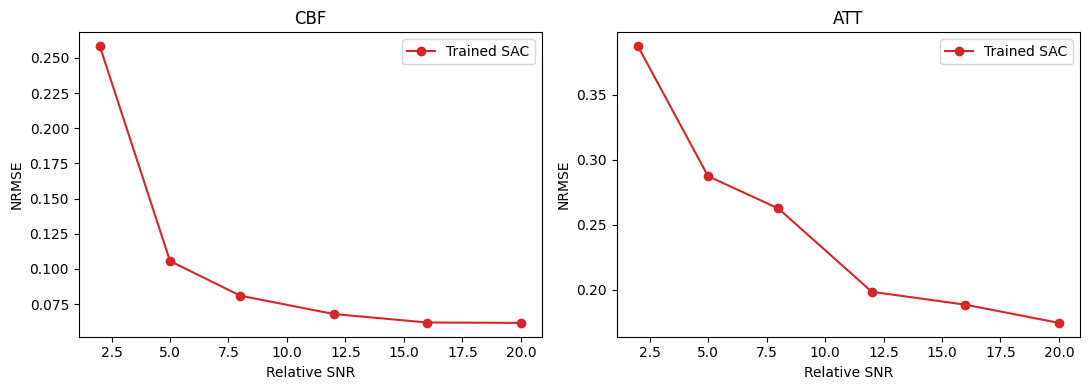

Saved independent-test plot: d:\reinforcement learning\asl-github-repo\experiments\rl_sac_4pld_trained\notebook_results\sac_nrmse_vs_snr.png
rSNR=  2.0  SAC CBF NRMSE=0.2584  SAC ATT NRMSE=0.3874
rSNR=  5.0  SAC CBF NRMSE=0.1056  SAC ATT NRMSE=0.2874
rSNR=  8.0  SAC CBF NRMSE=0.0810  SAC ATT NRMSE=0.2626
rSNR= 12.0  SAC CBF NRMSE=0.0679  SAC ATT NRMSE=0.1985
rSNR= 16.0  SAC CBF NRMSE=0.0619  SAC ATT NRMSE=0.1886
rSNR= 20.0  SAC CBF NRMSE=0.0617  SAC ATT NRMSE=0.1746


In [40]:
rows = evaluate_vs_snr(agent, args, args.device)
snr_vals = [r[0] for r in rows]
cbf_nrmse_vals = [r[1] for r in rows]
att_nrmse_vals = [r[2] for r in rows]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(snr_vals, cbf_nrmse_vals, marker="o", color="tab:red", label="Trained SAC")
axes[0].set_xlabel("Relative SNR")
axes[0].set_ylabel("NRMSE")
axes[0].set_title("CBF")
axes[0].legend()

axes[1].plot(snr_vals, att_nrmse_vals, marker="o", color="tab:red", label="Trained SAC")
axes[1].set_xlabel("Relative SNR")
axes[1].set_ylabel("NRMSE")
axes[1].set_title("ATT")
axes[1].legend()

plt.tight_layout()
plot_path = os.path.join(args.out_dir, "sac_nrmse_vs_snr.png")
plt.savefig(plot_path, dpi=150)
plt.show()
print("Saved independent-test plot:", plot_path)
for snr, cbf_n, att_n in rows:
    print(f"rSNR={snr:5.1f}  SAC CBF NRMSE={cbf_n:.4f}  SAC ATT NRMSE={att_n:.4f}")


## 10. Detailed Metrics vs SNR (RMSE / MAE / CCC)

Complements the paper-style NRMSE sweep above with raw CBF RMSE/MAE and ATT RMSE/MAE in
seconds, plus Lin's concordance correlation coefficient (CCC), matching the comparison table.

In [41]:
def evaluate_metrics_vs_snr(agent, args, device, snr_grid=[10, 15, 20], n_pairs=2000):
    print(f"{'SNR':<5} | {'CBF RMSE':<10} | {'CBF MAE':<9} | {'CBF CCC':<8} | {'ATT RMSE':<10} | {'ATT MAE':<9} | {'ATT CCC':<8}")
    print("-" * 85)
    def ccc(true, pred, eps=1e-8):
        true_mean, pred_mean = true.mean(), pred.mean()
        true_var = true.var(unbiased=False)
        pred_var = pred.var(unbiased=False)
        covariance = ((true - true_mean) * (pred - pred_mean)).mean()
        return (2.0 * covariance / (true_var + pred_var +
                                     (true_mean - pred_mean).square() + eps)).item()
    for snr in snr_grid:
        # Initialize environment at the specific SNR without clean fraction
        env = ASLEnvironment(batch_size=n_pairs, max_steps=args.max_steps,
                             snr_min=snr, snr_max=snr, clean_fraction=0.0, device=device)
        env.lm_handoff_step = args.max_steps
        state = env.reset()
        # Rollout the evaluation episode deterministically (Phase 1 SAC deltas,
        # then the environment's own DPAC hand-off into the LM solver for the
        # tail of the episode -- same dynamics as training/eval elsewhere)
        with torch.no_grad():
            for _ in range(args.max_steps):
                action = agent.act(state, deterministic=True)
                state, _, _, _ = env.step(action)
        # Extract ground truth and estimated parameters
        cbf_t = env.cbf_true
        cbf_e = env.cbf_est
        att_t = env.att_true
        att_e = env.att_est
        # CBF is reported in the paper's native mL/100 g/min units.
        cbf_rmse = torch.sqrt(torch.mean((cbf_t - cbf_e) ** 2)).item()
        cbf_mae = torch.mean(torch.abs(cbf_t - cbf_e)).item()
        cbf_ccc = ccc(cbf_t, cbf_e)
        # ATT is reported in seconds to match the comparison table.
        att_t_sec = att_t  # FIX: Already in seconds
        att_e_sec = att_e  # FIX: Already in seconds
        att_rmse = torch.sqrt(torch.mean((att_t_sec - att_e_sec) ** 2)).item()
        att_mae = torch.mean(torch.abs(att_t_sec - att_e_sec)).item()
        att_ccc = ccc(att_t_sec, att_e_sec)
        print(f"{snr:<5.1f} | {cbf_rmse:<10.4f} | {cbf_mae:<9.4f} | {cbf_ccc:<8.4f} | {att_rmse:<10.4f} | {att_mae:<9.4f} | {att_ccc:<8.4f}")
# Execute the metric evaluation
evaluate_metrics_vs_snr(agent, args, args.device, snr_grid=[10, 15, 20], n_pairs=2000)


SNR   | CBF RMSE   | CBF MAE   | CBF CCC  | ATT RMSE   | ATT MAE   | ATT CCC 
-------------------------------------------------------------------------------------
10.0  | 3.7462     | 2.8706    | 0.9915   | 0.3877     | 0.2536    | 0.8585  
15.0  | 3.1736     | 2.3841    | 0.9936   | 0.3161     | 0.2190    | 0.9050  
20.0  | 3.1335     | 2.2952    | 0.9942   | 0.3242     | 0.2189    | 0.9031  


In [42]:
# Final independent test report for the trained SAC policy.
def collect_detailed_metrics(agent, args, device, snr_grid=(10, 15, 20), n_pairs=2000):
    records = {}
    for snr in snr_grid:
        env = ASLEnvironment(batch_size=n_pairs, max_steps=args.max_steps,
                             snr_min=snr, snr_max=snr, clean_fraction=0.0, device=device)
        env.lm_handoff_step = args.max_steps
        state = env.reset()
        with torch.no_grad():
            for _ in range(args.max_steps):
                state, _, _, _ = env.step(agent.act(state, deterministic=True))
        cbf_t, cbf_e = env.cbf_true, env.cbf_est
        att_t, att_e = env.att_true, env.att_est  # FIX: Already in seconds
        def ccc(true, pred, eps=1e-8):
            return (2 * ((true - true.mean()) * (pred - pred.mean())).mean() /
                    (true.var(unbiased=False) + pred.var(unbiased=False) +
                     (true.mean() - pred.mean()).square() + eps)).item()
        records[snr] = {
            "cbf_rmse": torch.sqrt((cbf_t - cbf_e).square().mean()).item(),
            "cbf_mae": (cbf_t - cbf_e).abs().mean().item(),
            "cbf_ccc": ccc(cbf_t, cbf_e),
            "att_rmse": torch.sqrt((att_t - att_e).square().mean()).item(),
            "att_mae": (att_t - att_e).abs().mean().item(),
            "att_ccc": ccc(att_t, att_e),
        }
    return records
assert isinstance(agent, SACAgent)
TEST_SEED = 20260919
np.random.seed(TEST_SEED)
torch.manual_seed(TEST_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TEST_SEED)
sac_metrics = collect_detailed_metrics(agent, args, args.device)
baseline_metrics = evaluate_grid_baseline(args, args.device)
print("=" * 72)
print("FINAL RL RESULT: TRAINED SAC POLICY")
print("STATUS: COMPLETED")
print("TEST SET: independent fresh synthetic population")
print("MODEL:", os.path.join(args.out_dir, "sac_asl_final.pth"))
print("TRAINING LOG:", os.path.join(args.out_dir, "train_log.csv"))
for snr, metric in sac_metrics.items():
    print(f"SAC SNR={snr} | CBF RMSE={metric['cbf_rmse']:.4f}, MAE={metric['cbf_mae']:.4f}, CCC={metric['cbf_ccc']:.4f} | "
          f"ATT RMSE={metric['att_rmse']:.4f}s, MAE={metric['att_mae']:.4f}s, CCC={metric['att_ccc']:.4f}")
print("BASELINE ABLATION: 31x31 observable grid initializer")
for snr, metric in baseline_metrics.items():
    print(f"BASELINE SNR={snr} | CBF RMSE={metric['cbf_rmse']:.4f} | ATT RMSE={metric['att_rmse']:.4f}s")
print("DECISION: report SAC as the RL result; baseline remains separate")
print("=" * 72)


FINAL RL RESULT: TRAINED SAC POLICY
STATUS: COMPLETED
TEST SET: independent fresh synthetic population
MODEL: d:\reinforcement learning\asl-github-repo\experiments\rl_sac_4pld_trained\notebook_results\sac_asl_final.pth
TRAINING LOG: d:\reinforcement learning\asl-github-repo\experiments\rl_sac_4pld_trained\notebook_results\train_log.csv
SAC SNR=10 | CBF RMSE=3.6187, MAE=2.7533, CCC=0.9916 | ATT RMSE=0.3732s, MAE=0.2414s, CCC=0.8707
SAC SNR=15 | CBF RMSE=3.2380, MAE=2.4567, CCC=0.9938 | ATT RMSE=0.3197s, MAE=0.2166s, CCC=0.9082
SAC SNR=20 | CBF RMSE=3.0291, MAE=2.2440, CCC=0.9943 | ATT RMSE=0.3143s, MAE=0.2164s, CCC=0.9065
BASELINE ABLATION: 31x31 observable grid initializer
BASELINE SNR=10 | CBF RMSE=4.4411 | ATT RMSE=0.0004s
BASELINE SNR=15 | CBF RMSE=4.0992 | ATT RMSE=0.0004s
BASELINE SNR=20 | CBF RMSE=3.7563 | ATT RMSE=0.0004s
DECISION: report SAC as the RL result; baseline remains separate
